<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 2, Red neuronal para estimar profundidad**


Vamos a entrenar desde cero (salvo el encoder) una red que recibe una foto ℓ y devuelve un mapa de profundidad ẑ:

$$\hat{\mathbf{z}} = h_\theta(\boldsymbol{\ell})$$

- **Datos:** NYU Depth v2, 1449 fotos de interiores con su profundidad medida por un Kinect
- **Red:** encoder ResNet-18 preentrenado en ImageNet y un decoder con conexiones de salto
- **Pérdida:** la invariante a escala

al final la probamos con fotos que nunca vio, la comparamos con una línea base que no aprende nada y la usamos con una foto propia

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import h5py
import matplotlib.pyplot as plt

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("usando:", dispositivo)

usando: cuda


**1. Datos**

Descargamos el archivo con las 1449 fotos etiquetadas (2.8 GB, tarda unos minutos)
* primero se intenta una copia en HuggingFace, que suele ser más rápida
* si falla se usa el servidor de NYU

In [ ]:
import os, glob, shutil

ARCHIVO = "nyu_depth_v2_labeled.mat"
URL_HF = "https://huggingface.co/datasets/kronecker0122/nyuv2/resolve/main/nyuv2.tar.zst.part-00"
URL_NYU = "http://horatio.cs.nyu.edu/mit/silberman/nyu_depth_v2/nyu_depth_v2_labeled.mat"

if not os.path.exists(ARCHIVO):
    # 1. copia en Hugging Face: un .tar.zst con el .mat adentro; se descomprime mientras baja
    !wget -q --show-progress -O - {URL_HF} | tar --zstd -xf -
    encontrados = glob.glob("**/" + ARCHIVO, recursive=True)
    if encontrados:
        shutil.move(encontrados[0], ARCHIVO)

if not os.path.exists(ARCHIVO) or os.path.getsize(ARCHIVO) < 2e9:
    # 2. si falló, servidor original de NYU (más lento)
    !wget -q --show-progress -O {ARCHIVO} {URL_NYU}

print(f"{ARCHIVO}: {os.path.getsize(ARCHIVO) / 1e9:.2f} GB")

tar (grandchild): zstd: Cannot exec: No such file or directory
tar (grandchild): Error is not recoverable: exiting now
-                     0%[                    ]       0  --.-KB/s               tar: Child died with signal 13
tar: Error is not recoverable: exiting now
-                     0%[                    ]  13.55K  6.54KB/s    in 2.1s    
nyu_depth_v2_labele 100%[===================>]   2.77G  26.9MB/s    in 1m 57s  
nyu_depth_v2_labeled.mat: 2.97 GB


* el archivo guarda las fotos en 640 × 480, las reducimos a 256 × 192 para que el entrenamiento sea rápido
* la profundidad z está en metros

In [ ]:
ALTO, ANCHO = 192, 256

# leemos de a 100 fotos para no llenar la memoria
lista_ell, lista_z = [], []

# abre el archivo en modo lectura, aunque es un .mat de MATLAB, por dentro es un archivo HDF5 por eso se abre con h5py
with h5py.File("nyu_depth_v2_labeled.mat", "r") as f:
    for i in range(0, len(f["images"]), 100):
        # MATLAB guarda las matrices “traspuestas” con el ancho antes que el alto
        # intercambiamo los dos últimos ejes las deja como (100, 3, 480, 640), que es lo que espera PyTorch: (fotos, canales, alto, ancho)
        ell = torch.from_numpy(f["images"][i:i + 100]).permute(0, 1, 3, 2).float() / 255   # (100, 3, 480, 640)
        z = torch.from_numpy(f["depths"][i:i + 100]).permute(0, 2, 1)[:, None]  # (100, 1, 480, 640)

        # Achica las fotos a 192 × 256 y las guarda en la lista, bilinear: cada píxel nuevo es un promedio suave de sus vecinos
        # antialias=True: antes de volverlo pequeño, suaviza un poco para que no aparezcan bordes serruchados
        lista_ell.append(F.interpolate(ell, size=(ALTO, ANCHO), mode="bilinear", antialias=True))

        # achica los mapas de profundidad, pero con nearest: cada píxel nuevo copia el valor del píxel original más cercano, sin promediar
        lista_z.append(F.interpolate(z, size=(ALTO, ANCHO), mode="nearest"))

In [ ]:
imagenes, profundidades = torch.cat(lista_ell), torch.cat(lista_z)
print(imagenes.shape, profundidades.shape)
print(f"z entre {profundidades.min():.2f} y {profundidades.max():.2f} m")

torch.Size([1449, 3, 192, 256]) torch.Size([1449, 1, 192, 256])
z entre 0.71 y 9.99 m


* las fotos vienen ordenadas por habitación, y fotos seguidas son casi iguales
* si separáramos al azar, la red vería en el entrenamiento fotos casi idénticas a las de prueba
* por eso separamos por bloques de 25 fotos: uno de cada seis bloques queda para prueba

In [ ]:
indices = np.arange(len(imagenes))
es_prueba = (indices // 25) % 6 == 0

ell_entren, z_entren = imagenes[~es_prueba], profundidades[~es_prueba]
ell_prueba, z_prueba = imagenes[es_prueba], profundidades[es_prueba]
print(f"entrenamiento: {len(ell_entren)} fotos   prueba: {len(ell_prueba)} fotos")

entrenamiento: 1199 fotos   prueba: 250 fotos


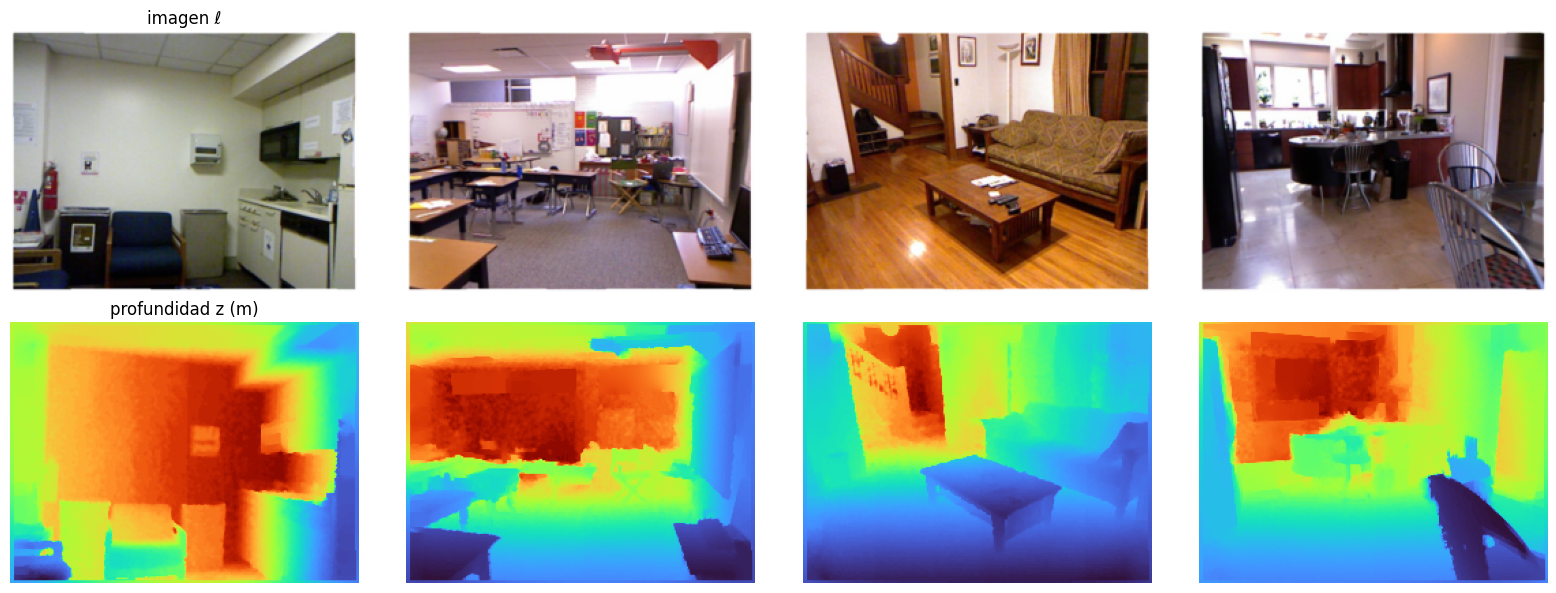

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for k in range(4):
    i = k * 300
    ax[0, k].imshow(imagenes[i].permute(1, 2, 0))
    ax[1, k].imshow(profundidades[i, 0], cmap="turbo")
    ax[0, k].axis("off"); ax[1, k].axis("off")
ax[0, 0].set_title("imagen ℓ"); ax[1, 0].set_title("profundidad z (m)")
plt.tight_layout()

**2. La red**

Es un encoder-decoder con conexiones de salto (U-Net):

- **Encoder:** ResNet-18 preentrenada, reduce la imagen en cinco etapas, hasta 1/32 del tamaño, y en cada etapa guarda los features
- **Decoder:** vuelve a agrandar paso a paso. En cada paso junta lo que viene de abajo (qué hay en la escena) con los features del encoder del mismo tamaño (dónde están los bordes)
- **Salida:** un valor por píxel, el logaritmo de la profundidad, así la red trabaja con errores relativos

In [ ]:
resnet = torchvision.models.resnet18(weights="IMAGENET1K_V1")

encoder = nn.ModuleList([
    nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu),   # 1/2,  64 canales
    nn.Sequential(resnet.maxpool, resnet.layer1),   # 1/4,  64
    resnet.layer2,  # 1/8,  128
    resnet.layer3,  # 1/16, 256
    resnet.layer4,  # 1/32, 512
])

def bloque(c_entrada, c_salida):
    return nn.Sequential(
        nn.Conv2d(c_entrada, c_salida, 3, padding=1),
        nn.BatchNorm2d(c_salida),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_salida, c_salida, 3, padding=1),
        nn.BatchNorm2d(c_salida),
        nn.ReLU(inplace=True),
    )

decoder = nn.ModuleList([bloque(512 + 256, 256),
                         bloque(256 + 128, 128),
                         bloque(128 + 64, 64),
                         bloque(64 + 64, 32)])
cabeza = nn.Conv2d(32, 1, 1)

red = nn.ModuleDict({"encoder": encoder, "decoder": decoder, "cabeza": cabeza}).to(dispositivo)
print(f"parámetros: {sum(p.numel() for p in red.parameters()) / 1e6:.1f} M")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


parámetros: 14.3 M


**Forward**

* los siguientes datos son el promedio y el desvío de los colores rojo, verde y azul en ImageNet
* la ResNet se entrenó viendo fotos normalizadas con estos números, así que hay que le damos en el mismo formato
* .view(1, 3, 1, 1) les da la forma (1 foto, 3 canales, 1, 1) para que se apliquen a cada píxel de cada foto

In [ ]:
MEDIA = torch.tensor([0.485, 0.456, 0.406], device=dispositivo).view(1, 3, 1, 1)
DESVIO = torch.tensor([0.229, 0.224, 0.225], device=dispositivo).view(1, 3, 1, 1)

In [ ]:
def h(ell):
    # centra los colores en 0 y los escala, igual que en ImageNet
    x = (ell - MEDIA) / DESVIO

    # baja por el encoder
    features = []
    for etapa in red["encoder"]:
        x = etapa(x)
        features.append(x)

    # sube por el decoder
    x = features[-1]
    for etapa, salto in zip(red["decoder"], reversed(features[:-1])):
        # agranda x al tamaño exacto del salto, por ejemplo de 6 × 8 a 12 × 16
        x = F.interpolate(x, size=salto.shape[-2:], mode="bilinear", align_corners=False)

        # skip-connection
        x = etapa(torch.cat([x, salto], dim=1))

    # volver al tamaño original y aplicar la cabeza
    x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
    return red["cabeza"](x)

with torch.no_grad():
    print("salida:", h(ell_entren[:2].to(dispositivo)).shape)

salida: torch.Size([2, 1, 192, 256])


**3. La pérdida invariante a escala**

nos quedamos solo con los píxeles que el Kinect sí midió

Con d = log ẑ − log z en cada píxel válido:

$$d_i = \log \hat{z}_i - \log z_i, \qquad i \in \{\, i : z_i > 0.1 \,\}$$

$$L = \operatorname{mean}\left(d^2\right) - \lambda \, \left(\operatorname{mean}(d)\right)^2$$

* con λ = 0, la red tiene que acertar los metros exactos
* con λ = 1, solo tiene que acertar la forma de la escena (qué está más cerca y qué más lejos), y equivocarse en la escala no le cuesta nada
* usamos λ = 0.85: la red se enfoca casi toda en la forma, pero igual aprende algo de escala

In [ ]:
def perdida(log_z_hat, z, lam=0.85):
    valido = z > 0.1                     # el Kinect deja huecos y valores sin medir
    d = log_z_hat[valido] - torch.log(z[valido])
    return (d ** 2).mean() - lam * d.mean() ** 2

**4. Entrenar**

* en cada época mezclamos los índices y recorremos las fotos en lotes
* como aumento de datos, a la mitad de los lotes los volteamos horizontalmente (la profundidad se voltea igual)

In [ ]:
EPOCAS, LOTE = 25, 16
optimizador = torch.optim.AdamW(red.parameters(), lr=3e-4, weight_decay=1e-4)
pasos = EPOCAS * (len(ell_entren) // LOTE)

# cambia la tasa de aprendizaje durante el entrenamiento, empieza baja y sube de a poco hasta max_lr = 3e-4
planificador = torch.optim.lr_scheduler.OneCycleLR(optimizador, max_lr=3e-4, total_steps=pasos)

# evita que los gradientes se vuelvan cero
escalador = torch.amp.GradScaler(enabled=dispositivo == "cuda")

historial = []
for epoca in range(EPOCAS):
    red.train()
    orden = torch.randperm(len(ell_entren))
    total = 0.0
    for k in range(len(ell_entren) // LOTE):
        idx = orden[k * LOTE:(k + 1) * LOTE]
        ell = ell_entren[idx].to(dispositivo)
        z = z_entren[idx].to(dispositivo)
        if torch.rand(1) < 0.5:
            ell, z = ell.flip(-1), z.flip(-1)
        # autocast hace los cálculos en float16 y GradScaler evita que los gradientes
        # se pierdan por esa precisión menor
        with torch.autocast(device_type="cuda", enabled=dispositivo == "cuda"):
            log_z_hat = h(ell)
        L = perdida(log_z_hat.float(), z)

        optimizador.zero_grad()
        escalador.scale(L).backward()
        escalador.step(optimizador)
        escalador.update()
        planificador.step()
        total += L.item()

    historial.append(total / (len(ell_entren) // LOTE))
    print(f"época {epoca + 1:2d}   pérdida {historial[-1]:.4f}")

época  1   pérdida 0.2530
época  2   pérdida 0.1533
época  3   pérdida 0.1029
época  4   pérdida 0.0693
época  5   pérdida 0.0552
época  6   pérdida 0.0493
época  7   pérdida 0.0440
época  8   pérdida 0.0390
época  9   pérdida 0.0340
época 10   pérdida 0.0306
época 11   pérdida 0.0278
época 12   pérdida 0.0248
época 13   pérdida 0.0211
época 14   pérdida 0.0208
época 15   pérdida 0.0184
época 16   pérdida 0.0176
época 17   pérdida 0.0160
época 18   pérdida 0.0155
época 19   pérdida 0.0146
época 20   pérdida 0.0136
época 21   pérdida 0.0128
época 22   pérdida 0.0126
época 23   pérdida 0.0124
época 24   pérdida 0.0122
época 25   pérdida 0.0123


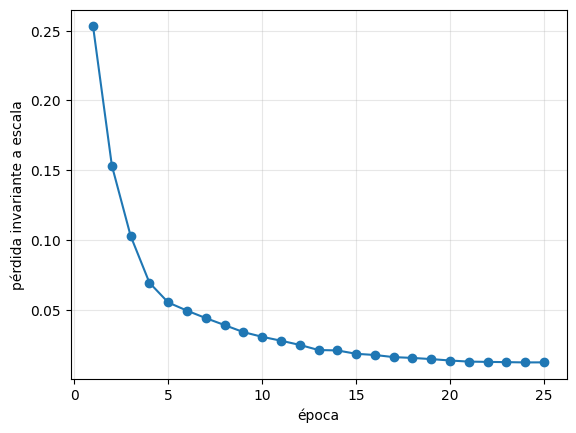

In [ ]:
plt.plot(range(1, EPOCAS + 1), historial, marker="o")
plt.xlabel("época"); plt.ylabel("pérdida invariante a escala"); plt.grid(alpha=0.3)

**5. Evaluación en fotos que nunca vio**

Usamos las métricas: AbsRel, δ₁ y RMSE, las calculamos de dos formas:

- **Métrica:** tal como sale de la red, en metros.
- **Alineada:** después de corregir la escala de cada foto con la mediana, como se hace para evaluar modelos relativos.

Para saber si la red aprendió algo, la comparamos con una línea base que no mira la foto: predice siempre la profundidad media del entrenamiento.

In [ ]:
def metricas(z_hat, z):
    # gual que en la pérdida, nos quedamos solo con los píxeles que el Kinect sí midió
    valido = z > 0.1
    z_hat, z = z_hat[valido], z[valido]
    # AbsRel (error relativo absoluto) nos dice el error de la red en proporcion a la distancia real
    abs_rel = (torch.abs(z_hat - z) / z).mean().item()
    # delta 1, nos dice el porcentaje de pixeles done la red no se equivoco en mas de un 25%
    # mientras mas alto mejor, si da 0.80 quiere decir que el 80% de los pixeles salio bien
    delta1 = (torch.maximum(z_hat / z, z / z_hat) < 1.25).float().mean().item()
    rmse = torch.sqrt(((z_hat - z) ** 2).mean()).item()
    return abs_rel, delta1, rmse

def alinear(z_hat, z):
    valido = z > 0.1
    # multiplicamos todo el mapa por un factor, para que la mediana de lo predicho coincida con la mediana de lo real
    return z_hat * torch.median(z[valido]) / torch.median(z_hat[valido])

red.eval()
with torch.no_grad():
    z_hat_prueba = torch.cat([torch.exp(h(ell_prueba[i:i + 32].to(dispositivo))).cpu()
                              for i in range(0, len(ell_prueba), 32)])

# baseline, un “modelo” que no mira la foto y dice siempre la misma profundidad en todos los píxeles
base = torch.full_like(z_prueba, z_entren[z_entren > 0.1].mean().item())

resultados = {
    "línea base (media)": metricas(base, z_prueba),
    "red, métrica": metricas(z_hat_prueba, z_prueba),
    "red, alineada": metricas(torch.stack([alinear(a, b) for a, b in zip(z_hat_prueba, z_prueba)]), z_prueba),
}
print(f"{'':<22}{'AbsRel':>8}{'δ1':>8}{'RMSE (m)':>10}")
for nombre, (abs_rel, delta1, rmse) in resultados.items():
    print(f"{nombre:<22}{abs_rel:>8.3f}{delta1:>8.3f}{rmse:>10.3f}")

                        AbsRel      δ1  RMSE (m)
línea base (media)       0.411   0.370     1.342
red, métrica             0.175   0.730     0.695
red, alineada            0.151   0.794     0.617


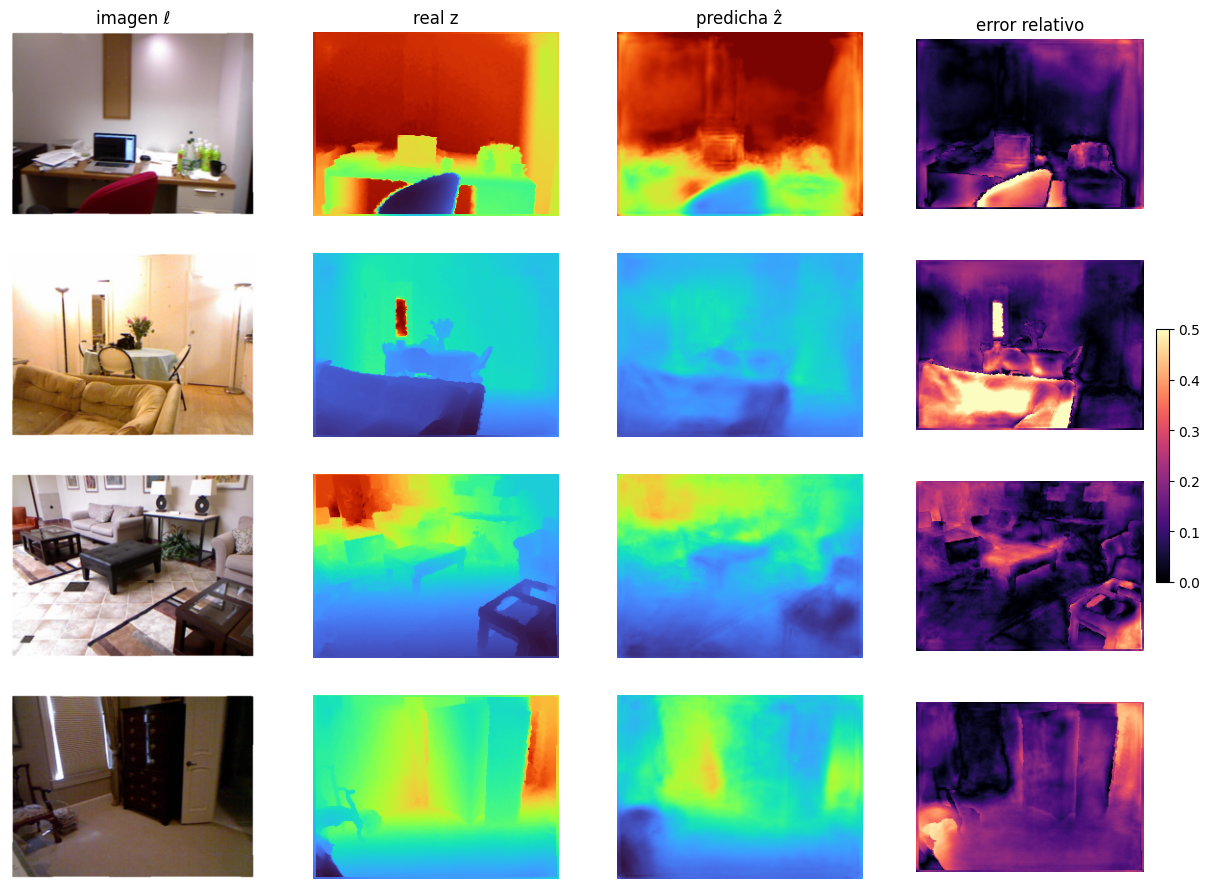

In [ ]:
fig, ax = plt.subplots(4, 4, figsize=(15, 11))
for fila, i in enumerate([3, 40, 90, 160]):
    z, z_hat = z_prueba[i, 0], z_hat_prueba[i, 0]
    vmin, vmax = z[z > 0.1].min(), z.max()
    ax[fila, 0].imshow(ell_prueba[i].permute(1, 2, 0))
    ax[fila, 1].imshow(z, cmap="turbo", vmin=vmin, vmax=vmax)
    ax[fila, 2].imshow(z_hat, cmap="turbo", vmin=vmin, vmax=vmax)
    im = ax[fila, 3].imshow(torch.abs(z_hat - z) / z * (z > 0.1), cmap="magma", vmin=0, vmax=0.5)
for x, titulo in zip(ax[0], ("imagen ℓ", "real z", "predicha ẑ", "error relativo")):
    x.set_title(titulo)
for x in ax.ravel():
    x.axis("off")
fig.colorbar(im, ax=ax[:, 3], fraction=0.05)

6. **De la profundidad a 3D**

Con la K del Kinect (escalada a 256 × 192), cada píxel se convierte en un punto:

$$X = (n - c_x)\frac{z}{a}, \qquad Y = (m - c_y)\frac{z}{b}, \qquad Z = z$$

In [ ]:
import plotly.graph_objects as go

escala = ANCHO / 640
a, b = 518.9 * escala, 519.5 * escala
c_x, c_y = 325.6 * escala, 253.7 * escala

def nube(ell, z, paso=2):
    m, n = torch.meshgrid(torch.arange(ALTO), torch.arange(ANCHO), indexing="ij")
    X, Y = (n - c_x) * z / a, (m - c_y) * z / b
    P = torch.stack([X, Y, z], -1)[::paso, ::paso].reshape(-1, 3).numpy()
    color = (ell.permute(1, 2, 0)[::paso, ::paso].reshape(-1, 3).numpy() * 255).astype(int)
    return go.Scatter3d(x=P[:, 0], y=P[:, 2], z=-P[:, 1], mode="markers",
                        marker=dict(size=1.5, color=[f"rgb({r},{g},{b_})" for r, g, b_ in color]))

i = 40
fig = go.Figure(nube(ell_prueba[i], z_hat_prueba[i, 0]))
fig.update_layout(scene=dict(aspectmode="data"), height=500, margin=dict(l=0, r=0, t=0, b=0))
fig.show()

**7. con una foto propia**

la red nunca vio su cámara, así que la escala en metros puede fallar, la forma debería verse bien

Saving images (30).jpeg to images (30).jpeg


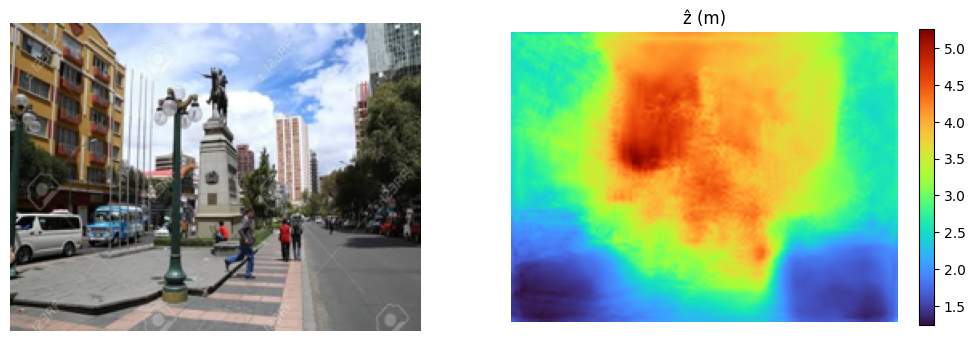

In [ ]:
from google.colab import files
from PIL import Image

nombre = list(files.upload())[0]
foto = Image.open(nombre).convert("RGB").resize((ANCHO, ALTO))
ell_propia = torch.from_numpy(np.array(foto)).permute(2, 0, 1).float()[None] / 255

with torch.no_grad():
    z_propia = torch.exp(h(ell_propia.to(dispositivo)))[0, 0].cpu()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(foto); ax[0].axis("off")
im = ax[1].imshow(z_propia, cmap="turbo"); ax[1].axis("off"); ax[1].set_title("ẑ (m)")
plt.colorbar(im, ax=ax[1], fraction=0.035)